# Informalidad laboral en México, 2T-2026: un análisis auditable y replicable

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/benjov/taller-claude-code-cide/blob/main/06-fuentes-auditables/ejemplo-final/informalidad_auditable.ipynb)

**Pregunta:** ¿Qué proporción de la población ocupada en México está en la informalidad laboral y cómo varía entre entidades?

**Qué hace este notebook**
1. Obtiene los **microdatos oficiales** de la ENOE (INEGI) y registra cada archivo en una **bitácora de fuentes** (URL original, fecha de consulta, tamaño y huella SHA-256).
2. **Replica** la Tasa de Informalidad Laboral 1 (TIL1) con criterios explícitos.
3. **Valida** el resultado contra las cifras publicadas por INEGI en sus boletines de prensa.
4. Contrasta con una segunda fuente (**ILOSTAT**, OIT) y explica las diferencias.
5. **Verifica** que todos los enlaces sigan vivos y exporta todo a Excel.

**Cómo usarlo**
- *Jupyter local:* `pip install -r requirements.txt` y ejecutar todo (Kernel → Restart & Run All).
- *Google Colab:* botón "Abrir en Colab" de arriba. No hace falta instalar nada; ejecutar todo (Entorno de ejecución → Ejecutar todas).

> Construido con Claude Code como ejemplo para el taller del CIDE. **Toda cifra de este notebook proviene de una fuente registrada en la bitácora.**

## 1. Parámetros
**`FUENTE_DATOS`** decide de dónde salen los archivos:
- `"repo"` *(por omisión)*: usa la copia guardada en el repositorio del taller (`../datos/`). Si no la encuentra, por ejemplo en Colab, la baja de GitHub. Es rápido y no depende de los servidores de INEGI.
- `"original"`: descarga cada archivo **directamente de INEGI y la OIT**, como lo haría un investigador desde cero.

En ambos casos se registra la URL original y se compara la huella SHA-256 con la del archivo del repositorio.
Para replicar **otro periodo** (cambiando `ANIO`/`TRIM`) use `"original"`: el repositorio solo trae 2026-T2.

In [1]:
import hashlib, platform, zipfile
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt

FUENTE_DATOS = "repo"          # "repo" o "original"
ANIO, TRIM = 2026, 2

CARPETA_REPO = Path("../datos")    # copia de los datos dentro del repositorio clonado
CARPETA_DATOS = Path("datos")      # aquí se guardan las descargas
URL_REPO = "https://github.com/benjov/taller-claude-code-cide/raw/main/06-fuentes-auditables/datos/"

URL_ENOE = (f"https://www.inegi.org.mx/contenidos/programas/enoe/15ymas/datosabiertos/"
            f"{ANIO}/conjunto_de_datos_enoe_{ANIO}_{TRIM}t_csv.zip")
URL_ILO = ("https://rplumber.ilo.org/data/indicator/"
           "?id=EMP_NIFL_SEX_RT_A&ref_area=MEX&format=.csv")
URL_BOLETIN = "https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/enoe/enoe2026_08.pdf"
URL_BOLETIN_EDO = "https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/enoe/enoe2026_08_{}.pdf"

# Huellas de las copias del repositorio (ver datos/FUENTES.md)
SHA_REPO = {
    "enoe_2026_2t_csv.zip": "9ef8877c363f6097da1a04b2077cbda96300cc474b38f835c4963d1dd8f953df",
    "ilostat_informalidad_mex.csv": "34471a75d355fc0dfe1783768f50586309b2241ea429ef0829f469a168a29601",
    "enoe2026_08.pdf": "74cfc4f19f98ea25ba20d0e0dc70557855050cc3399bbdc25dd46e066a0b8fca",
}

print("Periodo:", f"{ANIO}-T{TRIM}", "| Fuente de datos:", FUENTE_DATOS)
print("Ejecutado:", datetime.now(timezone.utc).isoformat(timespec="seconds"))

/Users/benjamin/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Periodo: 2026-T2 | Fuente de datos: repo
Ejecutado: 2026-11-21T19:09:17+00:00


## 2. Obtención de datos con bitácora de fuentes
Cada archivo se obtiene **una sola vez** (si ya existe, se reutiliza) y siempre se calcula su huella SHA-256.
Si alguien más obtiene la misma huella, está trabajando con **exactamente el mismo archivo**.

In [2]:
bitacora = []

def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def bajar(url, ruta):
    r = requests.get(url, timeout=300, headers={"User-Agent": "taller-cide-notebook"})
    r.raise_for_status()
    ruta.parent.mkdir(exist_ok=True)
    ruta.write_bytes(r.content)
    return r.status_code

def obtener(url_original, nombre, institucion, descripcion):
    if FUENTE_DATOS == "repo" and (CARPETA_REPO / nombre).exists():
        ruta, obtenido = CARPETA_REPO / nombre, "copia local del repositorio"
    else:
        ruta = CARPETA_DATOS / nombre
        origen = URL_REPO + nombre if FUENTE_DATOS == "repo" else url_original
        if ruta.exists():
            obtenido = f"reutilizado (ya descargado de {'GitHub' if FUENTE_DATOS == 'repo' else 'la fuente original'})"
        else:
            codigo = bajar(origen, ruta)
            obtenido = f"descargado de {'GitHub (repo)' if FUENTE_DATOS == 'repo' else 'la fuente original'} · HTTP {codigo}"
    huella = sha256(ruta)
    esperado = SHA_REPO.get(nombre)
    bitacora.append({
        "id": f"F{len(bitacora)+1:02d}",
        "institucion": institucion,
        "descripcion": descripcion,
        "url_original": url_original,
        "fecha_consulta_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "como_se_obtuvo": obtenido,
        "archivo_local": str(ruta),
        "bytes": ruta.stat().st_size,
        "sha256": huella,
        "igual_a_copia_del_repo": None if esperado is None else huella == esperado,
    })
    return ruta

zip_enoe = obtener(URL_ENOE, f"enoe_{ANIO}_{TRIM}t_csv.zip", "INEGI",
                   f"ENOE {ANIO}-T{TRIM}, microdatos (datos abiertos, CSV)")
csv_ilo = obtener(URL_ILO, "ilostat_informalidad_mex.csv", "OIT / ILOSTAT",
                  "Proporción de empleo informal, México, serie anual por sexo")
pdf_boletin = obtener(URL_BOLETIN, "enoe2026_08.pdf", "INEGI",
                      f"Boletín de prensa ENOE {ANIO}-T{TRIM}, nacional")

pd.DataFrame(bitacora)[["id", "institucion", "como_se_obtuvo", "bytes", "igual_a_copia_del_repo"]]

,id,institucion,como_se_obtuvo,bytes,igual_a_copia_del_repo
0,F01,INEGI,copia local del repositorio,40915330,True
1,F02,OIT / ILOSTAT,copia local del repositorio,4387,True
2,F03,INEGI,copia local del repositorio,531514,True


## 3. ¿Qué contiene el archivo? Inspección antes de calcular

In [3]:
z = zipfile.ZipFile(zip_enoe)
tablas = [n for n in z.namelist() if n.endswith(".csv") and "/conjunto_de_datos/" in n]
pd.DataFrame({"tabla": tablas,
              "MB": [round(z.getinfo(n).file_size / 1e6, 1) for n in tablas]})

,tabla,MB
0,conjunto_de_datos_coe1_enoe_2026_2t/conjunto_d...,131.6
1,conjunto_de_datos_coe2_enoe_2026_2t/conjunto_d...,68.5
2,conjunto_de_datos_hog_enoe_2026_2t/conjunto_de...,16.8
3,conjunto_de_datos_sdem_enoe_2026_2t/conjunto_d...,116.7
4,conjunto_de_datos_viv_enoe_2026_2t/conjunto_de...,12.5


In [4]:
base = f"conjunto_de_datos_sdem_enoe_{ANIO}_{TRIM}t"
dicc = pd.read_csv(z.open(f"{base}/diccionario_de_datos/diccionario_datos_sdem_enoe_{ANIO}_{TRIM}t.csv"))
VARS = ["r_def", "c_res", "eda", "clase2", "emp_ppal", "fac_tri", "sex", "cve_ent"]
col_var = [c for c in dicc.columns if dicc[c].astype(str).str.lower().isin(VARS).any()][0]
dicc[dicc[col_var].astype(str).str.lower().isin(VARS)]

,NOMBRE_CAMPO,LONGITUD,TIPO,NEMÓNICO,CATÁLOGO,RANGO_CLAVES
0,Resultado definitivo de la entrevista,2,C,r_def,r_def,"00,15 ..."
10,Entidad federativa,2,C,cve_ent,cve_ent,[01-32]
21,Pregunta 6 Condición de residencia,1,C,c_res,c_res,[1-3]
23,Pregunta 8 Sexo,1,C,sex,sex,"1,2"
24,Pregunta 9 Edad,2,C,eda,eda,00-99
52,Ponderador trimestral,6,N,fac_tri,NaN,1-999999
55,Clasificación de la población en ocupada y des...,1,N,clase2,clase2,[1-4]
106,Clasificación de empleos formales e informales...,1,N,emp_ppal,emp_ppal,[1-2]


## 4. Réplica de la TIL1
**Criterios (convención de INEGI para la tabla sociodemográfica, `sdem`):**

| Criterio | Variable | Valor |
|---|---|---|
| Entrevista completa | `r_def` | 0 |
| Residente habitual o nuevo residente | `c_res` | 1 o 3 |
| Población de 15 años y más | `eda` | 15–98 |
| Población ocupada | `clase2` | 1 |
| Empleo informal | `emp_ppal` | 1 |
| Factor de expansión trimestral | `fac_tri` | — |

$$\text{TIL1} = \frac{\sum \text{fac\_tri} \cdot [\text{emp\_ppal}=1]}{\sum \text{fac\_tri}} \times 100 \quad \text{(sobre la población ocupada)}$$

In [5]:
# Hallazgo de auditoría: el CSV principal no es UTF-8 puro (hay texto en Latin-1, p. ej. "INDEPENDIZ\xcb").
# Leemos en latin-1; las variables que usamos son numéricas y no se ven afectadas.
sdem = pd.read_csv(z.open(f"{base}/conjunto_de_datos/{base}.csv"), encoding="latin-1",
                   usecols=VARS, low_memory=False).apply(pd.to_numeric, errors="coerce")
print(f"Registros en la tabla sdem: {len(sdem):,}")

filtro = (sdem.r_def == 0) & sdem.c_res.isin([1, 3]) & sdem.eda.between(15, 98) & (sdem.clase2 == 1)
ocup = sdem[filtro].assign(informal=lambda d: (d.emp_ppal == 1) * d.fac_tri)

def til1(g):
    return pd.Series({"ocupados": g.fac_tri.sum(), "informales": g.informal.sum(),
                      "TIL1": 100 * g.informal.sum() / g.fac_tri.sum()})

nacional = til1(ocup)
print(f"Ocupados:   {nacional.ocupados/1e6:,.1f} millones")
print(f"Informales: {nacional.informales/1e6:,.1f} millones")
print(f"TIL1:       {nacional.TIL1:.1f} %")

Registros en la tabla sdem: 417,128
Ocupados:   60.0 millones
Informales: 33.1 millones
TIL1:       55.1 %


## 5. Validación contra lo publicado por INEGI
Las cifras de referencia se transcribieron de los boletines de prensa (25 de agosto de 2026).
Cada una lleva su URL para que cualquier lector pueda revisarla. Tolerancia: diferencia menor a 0.05 puntos (redondeo a un decimal).

In [6]:
ents = pd.read_csv(z.open(f"{base}/catalogos/cve_ent.csv"), dtype=str)
nombre_ent = dict(zip(ents.CVE_ENT.astype(int), ents.DESCRIP))

por_ent = ocup.groupby("cve_ent").apply(til1, include_groups=False)
por_ent_sexo = ocup.groupby(["cve_ent", "sex"]).apply(til1, include_groups=False)

publicadas = [  # (indicador, valor publicado, valor replicado, fuente)
    ("Nacional · TIL1 (%)", 55.1, nacional.TIL1, URL_BOLETIN),
    ("Nacional · informales (millones)", 33.1, nacional.informales / 1e6, URL_BOLETIN),
]
# Cuadro 1 de cada boletín estatal. OJO: el orden de columnas es Total, MUJERES, Hombres.
for clave, abrev, (t, m, h) in [(9, "CdMx", (45.3, 47.3, 43.6)),
                                (21, "Pue", (70.3, 72.4, 68.7)),
                                (24, "SLP", (54.9, 55.3, 54.6))]:
    url = URL_BOLETIN_EDO.format(abrev)
    publicadas += [(f"{nombre_ent[clave]} · TIL1 total", t, por_ent.loc[clave, "TIL1"], url),
                   (f"{nombre_ent[clave]} · TIL1 hombres", h, por_ent_sexo.loc[(clave, 1), "TIL1"], url),
                   (f"{nombre_ent[clave]} · TIL1 mujeres", m, por_ent_sexo.loc[(clave, 2), "TIL1"], url)]

validacion = pd.DataFrame(publicadas, columns=["indicador", "publicado", "replicado", "fuente"])
validacion["diferencia"] = (validacion.replicado - validacion.publicado).round(3)
validacion["coincide"] = validacion.diferencia.abs() <= 0.05  # cabe en el redondeo a un decimal
validacion["replicado"] = validacion.replicado.round(3)
print("✅ Todas las cifras coinciden" if validacion.coincide.all() else "⚠️ Hay diferencias: revisar")
validacion

✅ Todas las cifras coinciden


,indicador,publicado,replicado,fuente,diferencia,coincide
0,Nacional · TIL1 (%),55.1,55.103,https://www.inegi.org.mx/contenidos/saladepren...,0.003,True
1,Nacional · informales (millones),33.1,33.084,https://www.inegi.org.mx/contenidos/saladepren...,-0.016,True
2,Ciudad de México · TIL1 total,45.3,45.298,https://www.inegi.org.mx/contenidos/saladepren...,-0.002,True
3,Ciudad de México · TIL1 hombres,43.6,43.559,https://www.inegi.org.mx/contenidos/saladepren...,-0.041,True
4,Ciudad de México · TIL1 mujeres,47.3,47.262,https://www.inegi.org.mx/contenidos/saladepren...,-0.038,True
5,Puebla · TIL1 total,70.3,70.254,https://www.inegi.org.mx/contenidos/saladepren...,-0.046,True
6,Puebla · TIL1 hombres,68.7,68.679,https://www.inegi.org.mx/contenidos/saladepren...,-0.021,True
7,Puebla · TIL1 mujeres,72.4,72.430,https://www.inegi.org.mx/contenidos/saladepren...,0.030,True
8,San Luis Potosí · TIL1 total,54.9,54.886,https://www.inegi.org.mx/contenidos/saladepren...,-0.014,True
9,San Luis Potosí · TIL1 hombres,54.6,54.609,https://www.inegi.org.mx/contenidos/saladepren...,0.009,True


## 6. Informalidad por entidad federativa

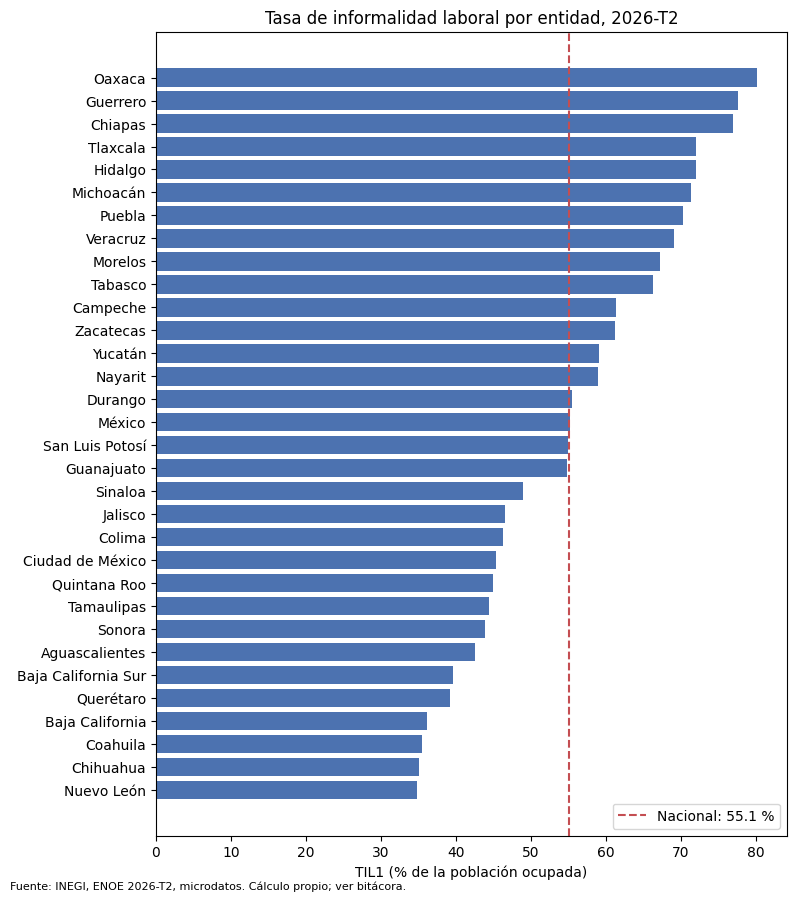

,cve_ent,entidad,ocupados,informales,TIL1
19,20,Oaxaca,1936523.0,1551876.0,80.1
11,12,Guerrero,1542295.0,1196886.0,77.6
6,7,Chiapas,2218580.0,1705666.0,76.9
28,29,Tlaxcala,670569.0,482893.0,72.0
12,13,Hidalgo,1476369.0,1062304.0,72.0
15,16,Michoacán,2218946.0,1582717.0,71.3
20,21,Puebla,3111161.0,2185703.0,70.3
29,30,Veracruz,3310652.0,2286068.0,69.1
16,17,Morelos,920190.0,618628.0,67.2
26,27,Tabasco,1085768.0,719018.0,66.2


In [7]:
tabla_ent = (por_ent.assign(entidad=lambda d: d.index.map(nombre_ent))
             .reset_index()[["cve_ent", "entidad", "ocupados", "informales", "TIL1"]]
             .sort_values("TIL1", ascending=False))

fig, ax = plt.subplots(figsize=(8, 9))
t = tabla_ent.sort_values("TIL1")
ax.barh(t.entidad, t.TIL1, color="#4C72B0")
ax.axvline(nacional.TIL1, color="#C44E52", ls="--", label=f"Nacional: {nacional.TIL1:.1f} %")
ax.set_xlabel("TIL1 (% de la población ocupada)")
ax.set_title(f"Tasa de informalidad laboral por entidad, {ANIO}-T{TRIM}")
ax.legend(loc="lower right")
fig.text(0.01, 0.005, f"Fuente: INEGI, ENOE {ANIO}-T{TRIM}, microdatos. Cálculo propio; ver bitácora.", fontsize=8)
fig.tight_layout()
fig.savefig(f"til1_entidades_{ANIO}t{TRIM}.png", dpi=150)
plt.show()
tabla_ent.head(10).round(1)

## 7. Segunda fuente: ILOSTAT (OIT)
La OIT publica una serie **anual** de empleo informal para México construida con la misma encuesta, pero con su **definición armonizada internacional**.
Por eso **no debe coincidir exactamente** con la TIL1 trimestral de INEGI. Documentar esa diferencia es parte de la auditoría.

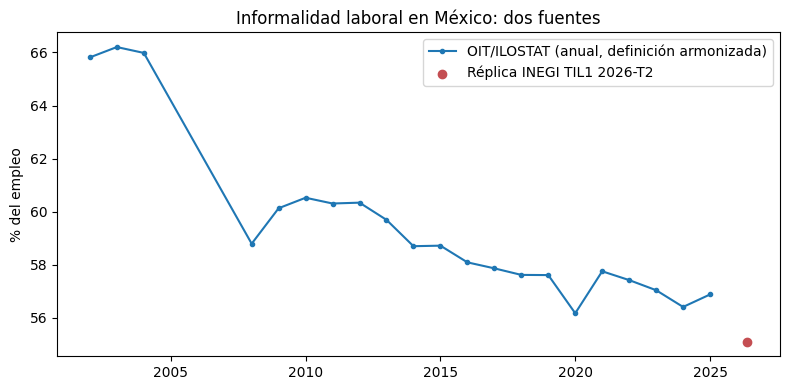

ILOSTAT 2025: 56.9 %  |  INEGI TIL1 2026-T2: 55.1 %


In [8]:
ilo = pd.read_csv(csv_ilo, encoding="utf-8-sig")
ilo_t = ilo[ilo.sex == "SEX_T"].sort_values("time")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ilo_t.time, ilo_t.obs_value, marker="o", ms=3, label="OIT/ILOSTAT (anual, definición armonizada)")
ax.scatter([ANIO + (TRIM - 0.5) / 4], [nacional.TIL1], color="#C44E52", zorder=3,
           label=f"Réplica INEGI TIL1 {ANIO}-T{TRIM}")
ax.set_ylabel("% del empleo"); ax.set_title("Informalidad laboral en México: dos fuentes")
ax.legend(); fig.tight_layout(); plt.show()

ultimo = ilo_t.iloc[-1]
print(f"ILOSTAT {int(ultimo.time)}: {ultimo.obs_value:.1f} %  |  INEGI TIL1 {ANIO}-T{TRIM}: {nacional.TIL1:.1f} %")

## 8. Verificación de enlaces
Se vuelve a consultar cada URL. Si un enlace muere en el futuro, esta tabla lo detecta.

In [9]:
urls = {f["url_original"] for f in bitacora} | set(validacion.fuente)

def estado_enlace(url):
    try:
        r = requests.head(url, timeout=30, allow_redirects=True,
                          headers={"User-Agent": "taller-cide-notebook"})
        if r.status_code >= 400:
            r = requests.get(url, timeout=30, stream=True, headers={"User-Agent": "taller-cide-notebook"})
            r.close()
        return r.status_code
    except requests.RequestException as e:
        return f"error: {type(e).__name__}"

enlaces = pd.DataFrame({"url": sorted(urls)})
enlaces["estado_http"] = enlaces.url.map(estado_enlace)
enlaces["verificado_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
enlaces

,url,estado_http,verificado_utc
0,https://rplumber.ilo.org/data/indicator/?id=EM...,200,2026-11-21T19:09:22+00:00
1,https://www.inegi.org.mx/contenidos/programas/...,200,2026-11-21T19:09:22+00:00
2,https://www.inegi.org.mx/contenidos/saladepren...,200,2026-11-21T19:09:22+00:00
3,https://www.inegi.org.mx/contenidos/saladepren...,200,2026-11-21T19:09:22+00:00
4,https://www.inegi.org.mx/contenidos/saladepren...,200,2026-11-21T19:09:22+00:00
5,https://www.inegi.org.mx/contenidos/saladepren...,200,2026-11-21T19:09:22+00:00


## 9. Exportar: bitácora, resultados y entorno

In [10]:
entorno = pd.DataFrame({"componente": ["python", "pandas", "requests", "sistema"],
                        "version": [platform.python_version(), pd.__version__,
                                    requests.__version__, platform.platform()]})
salida = f"informalidad_auditable_{ANIO}t{TRIM}.xlsx"
with pd.ExcelWriter(salida) as xls:
    pd.DataFrame(bitacora).to_excel(xls, sheet_name="bitacora_fuentes", index=False)
    validacion.to_excel(xls, sheet_name="validacion", index=False)
    tabla_ent.to_excel(xls, sheet_name="por_entidad", index=False)
    enlaces.to_excel(xls, sheet_name="estado_enlaces", index=False)
    entorno.to_excel(xls, sheet_name="entorno", index=False)
pd.DataFrame(bitacora).to_csv("bitacora_fuentes.csv", index=False)
print("Archivos generados:", salida, "· bitacora_fuentes.csv ·", f"til1_entidades_{ANIO}t{TRIM}.png")

Archivos generados: informalidad_auditable_2026t2.xlsx · bitacora_fuentes.csv · til1_entidades_2026t2.png


## 10. Lista de verificación para quien audite este trabajo
- [ ] La columna `igual_a_copia_del_repo` de la bitácora dice `True` (o sé explicar por qué no).
- [ ] La sección 5 muestra ✅ (la réplica coincide con lo publicado por INEGI).
- [ ] Todos los enlaces de la sección 8 responden con estado 200.
- [ ] Entiendo por qué ILOSTAT y la TIL1 de INEGI difieren (definición y periodicidad).
- [ ] Cambié `ANIO`/`TRIM` y el notebook corre para otro periodo.